In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
from astropy.time import Time
from astropy.table import  Table

In [3]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [4]:
import h5py
from astropy.io import ascii

In [5]:
import pickle
import svalue

In [6]:
from lmfit import Model

In [7]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [8]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [9]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs_2024.h5','r')

In [10]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]
overlap_mids=[]

for i,key in  enumerate(data['NEID']['coadds'].keys()):
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        #print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                #print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)
                overlap = data['overlaps'][i]
                mid=(overlap[0]+overlap[1])/2
                overlap_mids.append(Time(mid,format='jd').isot)

In [11]:
#check neid_indices = expres_indices and that their length is the same as overlap_mids
if neid_indices == expres_indices and len(neid_indices) == len(overlap_mids):

    print('everything matches:', neid_indices)
else:
    print('NEID and EXPRES indices do not match')

everything matches: ['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020', '0021', '0023', '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031', '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039', '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047', '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055', '0056', '0057', '0058', '0059', '0060']


In [12]:
order_centers=ascii.read('wavelength_centers.csv')

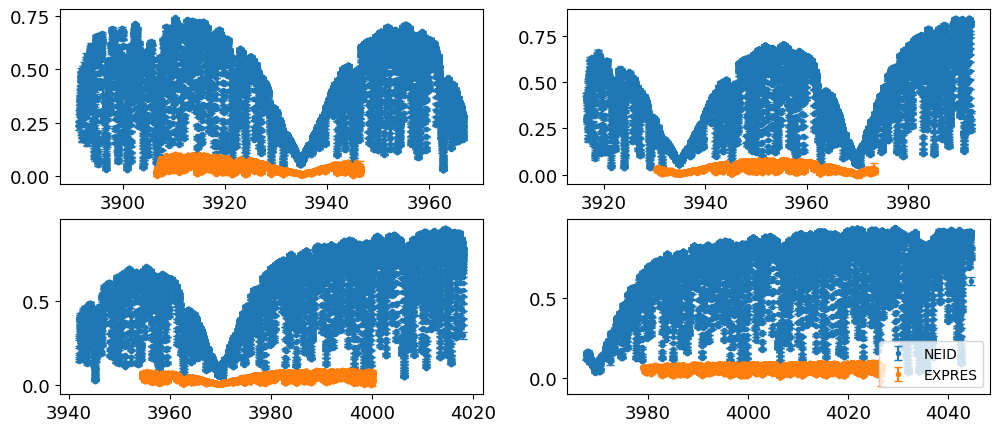

In [13]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s_values=[]
EXPRES_s_values=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    if i==2:
        for j in range(4):
            plt.subplot(2,2,j+1)
        
            plt.errorbar(w_NEID[j+4],s_NEID[j+4],yerr=e_NEID[j+4],fmt='.',label='NEID')
            plt.errorbar(w_EXPRES[j+4],s_EXPRES[j+4],yerr=e_EXPRES[j+4],fmt='.',label='EXPRES')
        plt.legend()
    
    sval_NEID=svalue.calc_s_value(w_NEID,s_NEID,e_NEID)
    NEID_s_values.append(sval_NEID)

    sval_EXPRES=svalue.calc_s_value(w_EXPRES,s_EXPRES,e_EXPRES)
    EXPRES_s_values.append(sval_EXPRES)
    
#convert both to numpy arrays
NEID_s_values = np.array(NEID_s_values)
EXPRES_s_values = np.array(EXPRES_s_values)

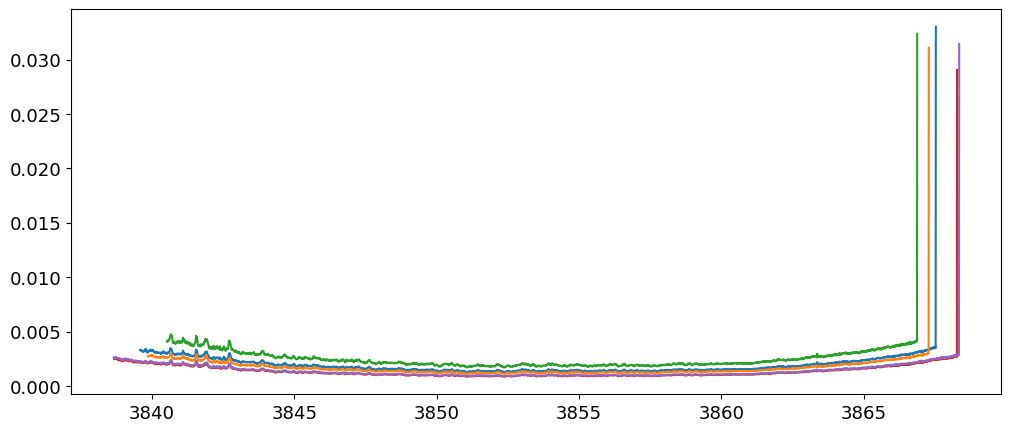

In [15]:
for i,idx in enumerate(neid_indices[:5]):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    plt.plot(w_EXPRES[1],e_EXPRES[1])

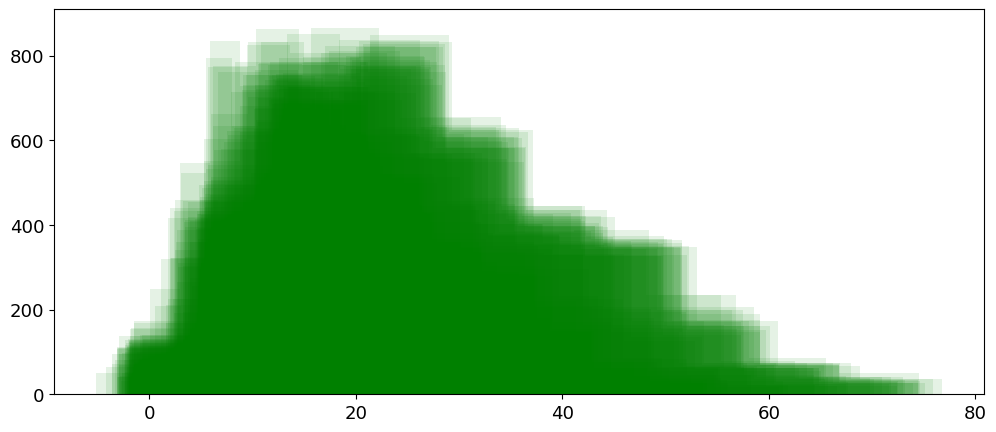

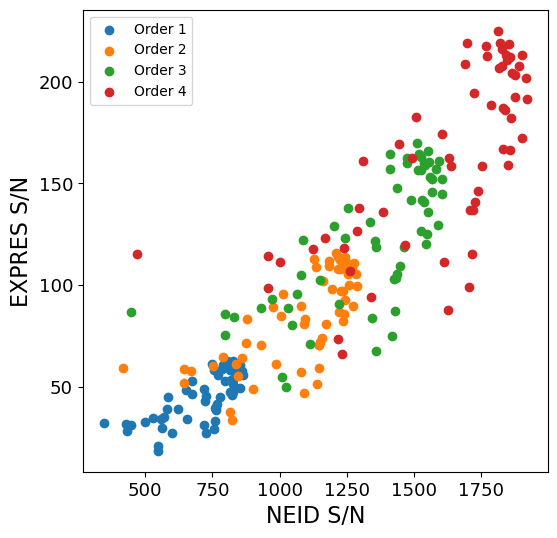

In [21]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=9
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in range(4):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


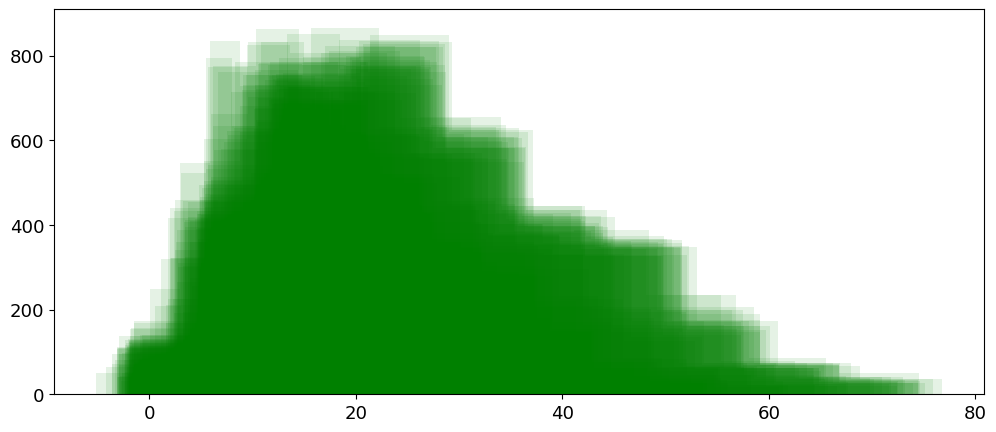

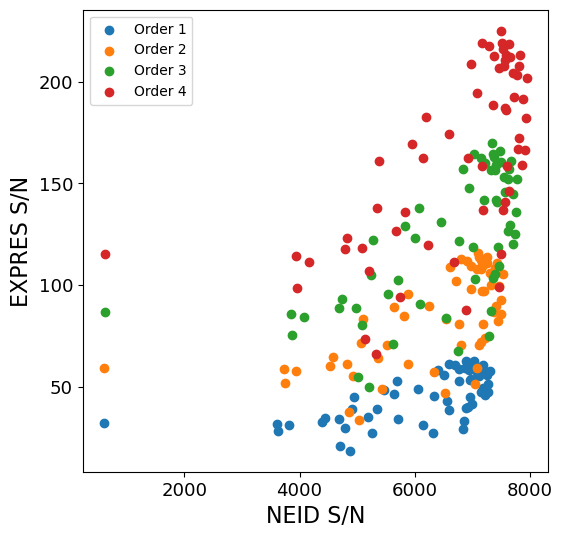

In [22]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=39
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in range(4):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


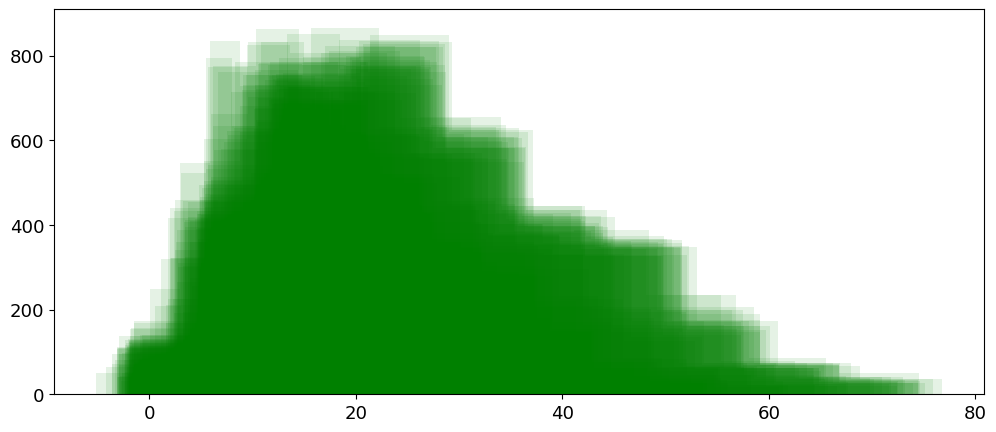

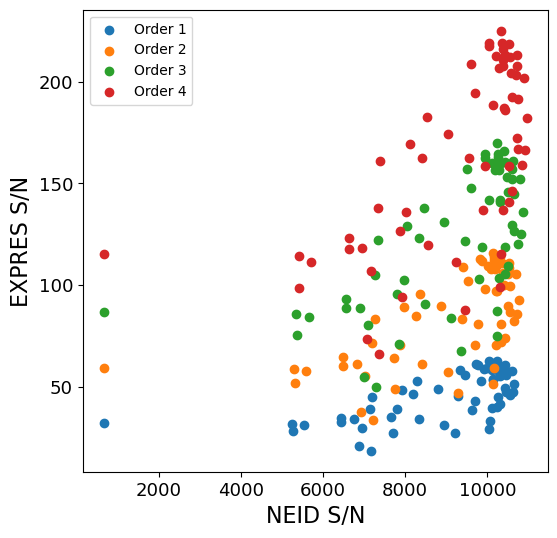

In [23]:
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
NEID_starting_idx=59
NEID_s2n=[]
EXPRES_s2n=[]
for i,idx in enumerate(neid_indices):

    w_NEID=np.array(data['NEID']['wls'][idx][NEID_starting_idx:])
    s_NEID=np.array(data['NEID']['coadds'][idx][NEID_starting_idx:])
    e_NEID=np.array(data['NEID']['uncs'][idx][NEID_starting_idx:])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    #print(e_EXPRES)

    N_s2n=[]
    E_s2n=[]
    for j in range(4):
        #calculate the s2n for the first 4 orders
        N_s_o=s_NEID[j]/e_NEID[j]
        E_s_o=s_EXPRES[j]/e_EXPRES[j]
        #print(f"Order {j+1} NEID s2n: {N_s_o}, EXPRES s2n: {E_s_o}")
        #take the 98th percentile of the s2n for this order
        N_s2n.append(np.nanpercentile(N_s_o,98))
        E_s2n.append(np.nanpercentile(E_s_o,98))
        if j==0:
            plt.hist(E_s_o,alpha=.1,color='green')
        

    NEID_s2n.append(N_s2n)
    EXPRES_s2n.append(E_s2n)
#convert both to numpy arrays
NEID_s2n = np.array(NEID_s2n)
EXPRES_s2n = np.array(EXPRES_s2n)

NEID_s2n_t=np.transpose(NEID_s2n)
EXPRES_s2n_t=np.transpose(EXPRES_s2n)
#make the plot a square
plt.figure(figsize=(6,6))
for j in range(NEID_s2n_t.shape[0]):
    plt.scatter(NEID_s2n_t[j],EXPRES_s2n_t[j],label=f'Order {j+1}')
plt.xlabel('NEID S/N')
plt.ylabel('EXPRES S/N')
plt.legend()


Correlation coefficient: -0.00582094918726053


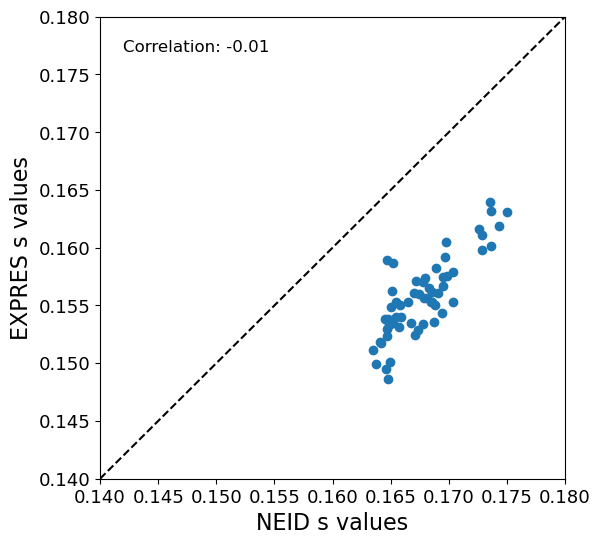

In [34]:
plot_min=.14
plot_max=.18

plt.figure(figsize=(6,6))
plt.scatter(NEID_s_values, EXPRES_s_values)
plt.xlabel('NEID s values')
plt.ylabel('EXPRES s values')
plt.xlim(plot_min,plot_max)
plt.ylim(plot_min,plot_max)
plt.plot([plot_min,plot_max],[plot_min,plot_max],'k--')

#calculate correlation coefficient
cor = np.corrcoef(NEID_s_values, EXPRES_s_values)[0,1]
#write it on the plot
plt.text(plot_min+.002, plot_max-.002, f"Correlation: {cor:.2f}", fontsize=12, verticalalignment='top')
print("Correlation coefficient:", cor)

Text(0, 0.5, 'EXPRES s values')

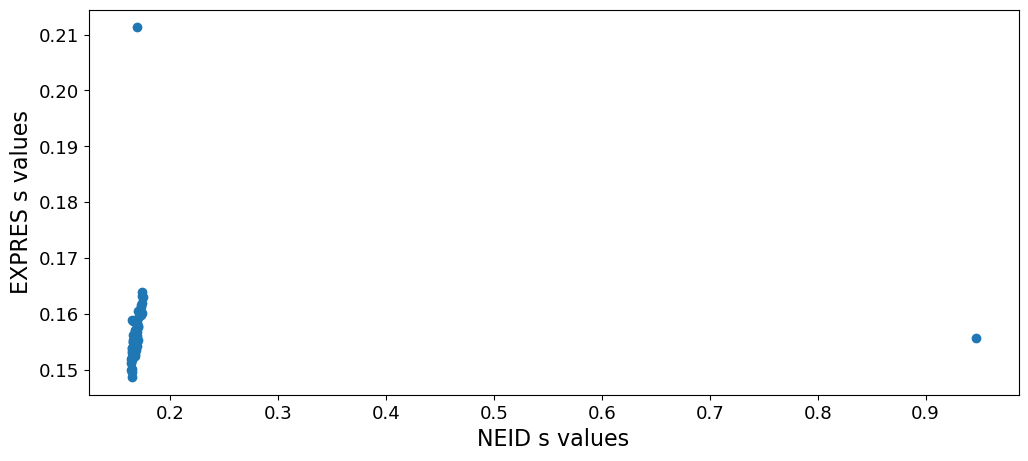

In [35]:
plt.scatter(NEID_s_values, EXPRES_s_values)
plt.xlabel('NEID s values')
plt.ylabel('EXPRES s values')


Correlation coefficient: 0.8260912617114394


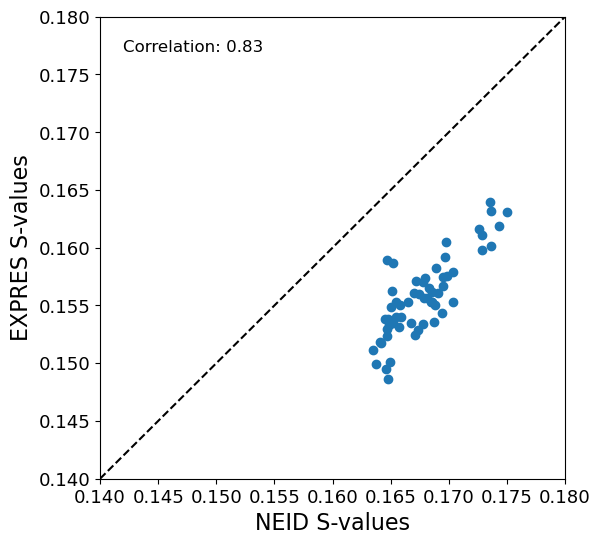

In [37]:
plot_min=.14
plot_max=.18

#good vals is where both are between .1 and .2  
good_vals = (NEID_s_values > .1) & (NEID_s_values < .2) & (EXPRES_s_values > .1) & (EXPRES_s_values < .2)


plt.figure(figsize=(6,6))
plt.scatter(NEID_s_values[good_vals], EXPRES_s_values[good_vals])
plt.xlabel('NEID S-values')
plt.ylabel('EXPRES S-values')
plt.xlim(plot_min,plot_max)
plt.ylim(plot_min,plot_max)
plt.plot([plot_min,plot_max],[plot_min,plot_max],'k--')

#calculate correlation coefficient
cor = np.corrcoef(NEID_s_values[good_vals], EXPRES_s_values[good_vals])[0,1]
#write it on the plot
plt.text(plot_min+.002, plot_max-.002, f"Correlation: {cor:.2f}", fontsize=12, verticalalignment='top')
print("Correlation coefficient:", cor)

In [20]:
def find_closest_order(central_wavelength,spectrograph):
    if spectrograph == 'NEID':
        wl_centers = order_centers['NEID_wl_center']
    elif spectrograph == 'EXPRES':
        wl_centers = order_centers['EXPRES_wl_center']
    
    distances = np.abs(wl_centers - central_wavelength)
    closest_order_idx = np.argmin(distances)
    
    return order_centers['order'][closest_order_idx]

In [21]:
find_closest_order(3901,'EXPRES')

np.int64(3)

In [ ]:
#save fit results to pickele file

#with open('aaa','wb') as f:
#    pickle.dump(fit_results,f)